<a href="https://colab.research.google.com/github/bibanaksu/PM25-Forecasting-GRU/blob/main/results/03/02_temporal_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install ruptures --quiet

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from scipy.stats import ks_2samp
import ruptures as rpt

SEED = 42
np.random.seed(SEED)

In [ ]:
!git clone https://github.com/bibanaksu/PM25-Forecasting-GRU.git
%cd PM25-Forecasting-GRU

Cloning into 'PM25-Forecasting-GRU'...
remote: Enumerating objects: 12, done.
remote: Counting objects: 100% (12/12), done.
remote: Compressing objects: 100% (10/10), done.
remote: Total 12 (delta 2), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (12/12), 31.55 KiB | 7.89 MiB/s, done.
Resolving deltas: 100% (2/2), done.
/content/PM25-Forecasting-GRU


In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"mariamohameddd","key":"f4f7a1325216ac62f5ce8ce384feb1f0"}'}

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

!kaggle datasets download -d sarahameziane/air-quality-mediterranean-basin-20162026
!unzip -o air-quality-mediterranean-basin-20162026.zip

Dataset URL: https://www.kaggle.com/datasets/sarahameziane/air-quality-mediterranean-basin-20162026
License(s): other
100% 8.80M/8.80M [00:00<00:00, 50.4MB/s]

Archive:  air-quality-mediterranean-basin-20162026.zip
  inflating: combined_gee_pm25.csv   
  inflating: gee_features_daily.csv  
  inflating: pm25.csv                


In [ ]:
import pandas as pd
import numpy as np

# 1. Load the raw files
pm_df = pd.read_csv('pm25.csv')
gee_df = pd.read_csv('gee_features_daily.csv')

# 2. Rename GEE lat/lon to match pm25
gee_df = gee_df.rename(columns={'lat': 'latitude', 'lon': 'longitude'})

# 3. The GEE data is gridded. Let's round the lat/lon to 2 decimals (~1km)
# so they match perfectly between the two datasets.
pm_df['lat_round'] = pm_df['latitude'].round(2)
pm_df['lon_round'] = pm_df['longitude'].round(2)
gee_df['lat_round'] = gee_df['latitude'].round(2)
gee_df['lon_round'] = gee_df['longitude'].round(2)

# 4. Merge on Date + Coordinates
df = pm_df.merge(
    gee_df,
    on=['date', 'lat_round', 'lon_round'],
    how='inner',
    suffixes=('', '_gee')
)

# Clean up the duplicate coordinate columns
df = df.drop(columns=['lat_round', 'lon_round', 'latitude_gee', 'longitude_gee', 'id'])

# 5. Reorder columns exactly as Person 1 had them
columns_order = [
    'date', 'datetime_utc', 'sensor_name', 'latitude', 'longitude',
    'temperature_celsius', 'pressure_mb', 'wind_u', 'wind_v',
    'NO2', 'CO', 'O3', 'AOD', 'pm25'
]
df = df[columns_order]

# Recreate the 'id' column (numeric representation of the station name)
df['id'] = df['sensor_name'].astype('category').cat.codes

# 6. Apply Person 1's exact cleaning rules
df_raw = df.copy()
pm = pd.to_numeric(df_raw["pm25"], errors="coerce")

invalid_mask = (
    pm.isna() |
    (pm <= 0) |
    (pm >= 500)
)

df_clean = df_raw.loc[~invalid_mask].copy()
df_clean["pm25"] = pd.to_numeric(df_clean["pm25"])

# 7. Save the final cleaned file
df_clean.to_csv("PM25_Cleaned.csv", index=False)

print("Merge and cleaning complete!")
print("Shape of cleaned data:", df_clean.shape)
display(df_clean.head(3))

Merge and cleaning complete!
Shape of cleaned data: (49949, 15)


,date,datetime_utc,sensor_name,latitude,longitude,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD,pm25,id
0,2016-11-25,2016-11-25 00:00:00,ONTINYENT,38.788056,-0.697222,6.493180,946.288660,0.230240,0.735303,NaN,NaN,NaN,0.111,2.750000,58
1,2016-11-25,2016-11-25 00:00:00,ALMASSORA-C. P. OCHANDO,39.945278,-0.056389,9.251236,993.626994,0.783218,-0.592618,NaN,NaN,NaN,0.022,11.666667,7
2,2016-11-30,2016-11-30 00:00:00,ALCORA,40.051944,-0.189722,10.044782,981.911432,-2.211047,-1.568971,NaN,NaN,NaN,0.238,2.400000,5


In [ ]:
!pip install ruptures --quiet

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from scipy.stats import ks_2samp
import ruptures as rpt

SEED = 42
np.random.seed(SEED)

# Load the data we just cleaned
df = pd.read_csv('PM25_Cleaned.csv')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values(['sensor_name', 'date']).reset_index(drop=True)

# Confirm Sentinel-5P columns
for c in ['NO2', 'CO', 'O3']:
    if c in df.columns:
        print(f"Found Sentinel column: {c}")

print("Stations:", df['sensor_name'].nunique())

Found Sentinel column: NO2
Found Sentinel column: CO
Found Sentinel column: O3
Stations: 94


In [ ]:
counts = df.groupby('sensor_name').size()
keep = counts[counts >= 30].index
print(f"Stations before: {df['sensor_name'].nunique()}, after: {len(keep)}")
df = df[df['sensor_name'].isin(keep)].copy()

Stations before: 94, after: 90


In [ ]:
import numpy as np

# Group by station and date, taking the mean for any numeric columns
# (This averages out duplicate rows if a station matched two grid points)
numeric_cols = df.select_dtypes(include=[np.number]).columns
df = df.groupby(['sensor_name', 'date'])[numeric_cols].mean().reset_index()

# Sort the data again
df = df.sort_values(['sensor_name', 'date']).reset_index(drop=True)

print("Data shape after removing duplicate dates:", df.shape)

Data shape after removing duplicate dates: (42201, 14)


In [ ]:
regularity = []
for station, g in df.groupby('sensor_name'):
    g = g.sort_values('date').set_index('date')
    ts = g['pm25'].asfreq('D')
    ts_clean = ts.dropna()

    if len(ts_clean) < 30:
        continue

    diffs_sec = g.index.to_series().diff().dt.total_seconds().dropna()
    full_range = pd.date_range(ts.index.min(), ts.index.max(), freq='D')
    pct_missing = 100 * (1 - len(g) / len(full_range))

    regularity.append({
        'sensor_name': station,
        'n_records': len(g),
        't_min': ts.index.min().date(),
        't_max': ts.index.max().date(),
        'sampling_interval_median_sec': float(diffs_sec.median()),
        'sampling_interval_std_sec':    float(diffs_sec.std()),
        'pct_missing_intervals':        float(pct_missing),
    })

reg_df = pd.DataFrame(regularity)
print(reg_df[['sampling_interval_median_sec','sampling_interval_std_sec','pct_missing_intervals']].describe())

       sampling_interval_median_sec  sampling_interval_std_sec  \
count                     90.000000               9.000000e+01   
mean                   88320.000000               5.515516e+05   
std                    12807.188992               1.017599e+06   
min                    86400.000000               8.443663e+04   
25%                    86400.000000               1.249388e+05   
50%                    86400.000000               3.899919e+05   
75%                    86400.000000               6.355513e+05   
max                   172800.000000               8.696687e+06   

       pct_missing_intervals  
count              90.000000  
mean               50.761040  
std                13.388026  
min                23.931624  
25%                40.918398  
50%                49.468632  
75%                60.019251  
max                87.678063  


In [ ]:
acf_rows = []
for station, g in df.groupby('sensor_name'):
    ts_clean = g.sort_values('date').set_index('date')['pm25'].asfreq('D').dropna()
    if len(ts_clean) < 30:
        continue
    nlags = min(24, len(ts_clean)//2 - 1)
    a = acf(ts_clean,  nlags=nlags, fft=False)
    p = pacf(ts_clean, nlags=nlags, method='ywm')
    acf_rows.append({
        'sensor_name': station,
        'acf_lag1':  float(a[1])  if len(a) > 1  else np.nan,
        'acf_lag7':  float(a[7])  if len(a) > 7  else np.nan,
        'acf_lag24': float(a[24]) if len(a) > 24 else np.nan,
        'pacf_lag1': float(p[1])  if len(p) > 1  else np.nan,
    })
acf_df = pd.DataFrame(acf_rows)
print(acf_df.describe())

        acf_lag1   acf_lag7  acf_lag24  pacf_lag1
count  90.000000  90.000000  83.000000  90.000000
mean    0.492810   0.115396   0.027814   0.492810
std     0.152551   0.115453   0.103107   0.152551
min     0.067245  -0.082701  -0.235600   0.067245
25%     0.377397   0.026874  -0.026288   0.377397
50%     0.517067   0.109870   0.024295   0.517067
75%     0.608047   0.184155   0.073107   0.608047
max     0.785862   0.451972   0.352496   0.785862


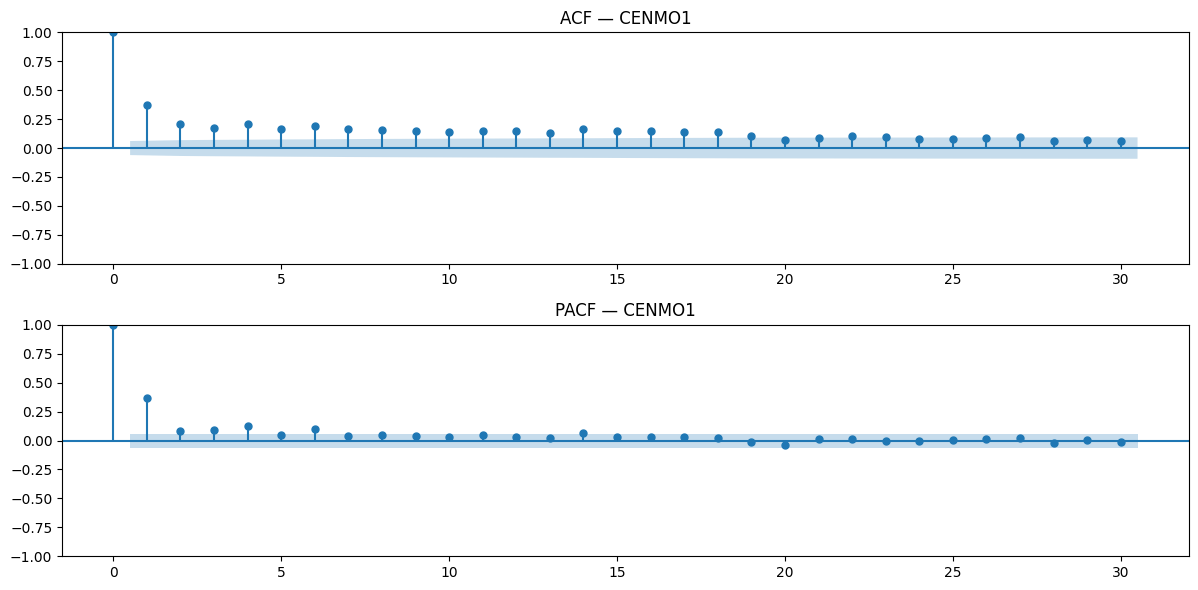

In [ ]:
top_station = df['sensor_name'].value_counts().index[0]
ts_plot = df[df['sensor_name']==top_station].set_index('date')['pm25'].asfreq('D').dropna()

fig, ax = plt.subplots(2, 1, figsize=(12, 6))
plot_acf(ts_plot,  lags=30, ax=ax[0], title=f'ACF — {top_station}')
plot_pacf(ts_plot, lags=30, ax=ax[1], title=f'PACF — {top_station}')
plt.tight_layout(); plt.savefig('acf_pacf.png', dpi=150); plt.show()

In [ ]:
tests_rows = []
for station, g in df.groupby('sensor_name'):
    ts_clean = g.sort_values('date').set_index('date')['pm25'].asfreq('D').dropna()
    if len(ts_clean) < 30:
        continue
    try:    adf_p  = float(adfuller(ts_clean, autolag='AIC')[1])
    except: adf_p  = np.nan
    try:    kpss_p = float(kpss(ts_clean, regression='c', nlags='auto')[1])
    except: kpss_p = np.nan
    try:    lb_p   = float(acorr_ljungbox(ts_clean, lags=[7], return_df=True)['lb_pvalue'].iloc[0])
    except: lb_p   = np.nan

    tests_rows.append({'sensor_name': station,
                       'adf_p': adf_p, 'kpss_p': kpss_p, 'ljung_box_p': lb_p})

tests_df = pd.DataFrame(tests_rows)
print("ADF stationary (p<0.05):", (tests_df['adf_p']  < 0.05).sum(), "/", len(tests_df))
print("KPSS stationary (p>0.05):",(tests_df['kpss_p'] > 0.05).sum(), "/", len(tests_df))
print("LB autocorr (p<0.05):    ", (tests_df['ljung_box_p'] < 0.05).sum(), "/", len(tests_df))

/tmp/ipykernel_1568/3286313941.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  try:    adf_p  = float(adfuller(ts_clean, autolag='AIC')[1])
/tmp/ipykernel_1568/3286313941.py:8: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  try:    kpss_p = float(kpss(ts_clean, regression='c', nlags='auto')[1])
/tmp/ipykernel_1568/3286313941.py:8: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default beha

ADF stationary (p<0.05): 85 / 90
KPSS stationary (p>0.05): 65 / 90
LB autocorr (p<0.05):     85 / 90


/tmp/ipykernel_1568/3286313941.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  try:    adf_p  = float(adfuller(ts_clean, autolag='AIC')[1])
/tmp/ipykernel_1568/3286313941.py:8: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  try:    kpss_p = float(kpss(ts_clean, regression='c', nlags='auto')[1])
/tmp/ipykernel_1568/3286313941.py:8: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default beha

In [ ]:
trend_rows = []
for station, g in df.groupby('sensor_name'):
    ts_clean = g.sort_values('date').set_index('date')['pm25'].asfreq('D').dropna()
    if len(ts_clean) < 30:
        continue

    # Trend
    x = np.arange(len(ts_clean))
    ols = sm.OLS(ts_clean.values, sm.add_constant(x)).fit()
    trend_slope = float(ols.params[1])
    trend_pval  = float(ols.pvalues[1])

    # Drift
    half = len(ts_clean)//2
    ks_stat, ks_p = ks_2samp(ts_clean.iloc[:half], ts_clean.iloc[half:])

    # Seasonality & Regimes
    monthly_med = ts_clean.groupby(ts_clean.index.month).median()
    seasonal_amp = float(monthly_med.max() - monthly_med.min())
    n_cycles = int(np.ceil((ts_clean.index.max() - ts_clean.index.min()).days / 365))
    try:
        algo = rpt.Pelt(model="rbf").fit(ts_clean.values.reshape(-1,1))
        regime_breaks = len(algo.predict(pen=10)) - 1
    except Exception:
        regime_breaks = np.nan

    # Thresholds
    n25 = int((ts_clean > 25).sum()); n50 = int((ts_clean > 50).sum())

    trend_rows.append({
        'sensor_name': station,
        'trend_slope_per_day': trend_slope,
        'trend_pval':          trend_pval,
        'target_drift_stat':   float(ks_stat),
        'target_drift_pval':   float(ks_p),
        'seasonal_amplitude':  seasonal_amp,
        'regime_breaks':       regime_breaks,
        'n_cycles_observed':   n_cycles,
        'n_days_above_25':     n25,
        'n_days_above_50':     n50,
        'pct_days_above_25':   100*n25/len(ts_clean),
        'pct_days_above_50':   100*n50/len(ts_clean)
    })

trend_df = pd.DataFrame(trend_rows)
print("Significant trend (p<0.05):", (trend_df['trend_pval'] < 0.05).sum(), "/", len(trend_df))
print("Significant drift (p<0.05):", (trend_df['target_drift_pval'] < 0.05).sum(), "/", len(trend_df))

Significant trend (p<0.05): 43 / 90
Significant drift (p<0.05): 51 / 90


In [ ]:
def missing_json(g, col):
    if col is None or col not in g.columns:
        return None
    s = g[col].isna()
    if s.sum() == 0:
        return json.dumps({})
    m = s.groupby(g.index.to_period('M')).mean() * 100
    return json.dumps({str(k): round(float(v), 2) for k, v in m.items()})

missing_rows = []
for station, g in df.groupby('sensor_name'):
    g = g.sort_values('date').set_index('date')
    missing_rows.append({
        'sensor_name': station,
        'no2_pct_missing_by_month': missing_json(g, 'NO2'),
        'co_pct_missing_by_month':  missing_json(g, 'CO'),
        'o3_pct_missing_by_month':  missing_json(g, 'O3'),
    })
missing_df = pd.DataFrame(missing_rows)

In [ ]:
# Merge everything
out = reg_df.merge(acf_df,   on='sensor_name', how='left') \
            .merge(tests_df, on='sensor_name', how='left') \
            .merge(trend_df, on='sensor_name', how='left') \
            .merge(missing_df,on='sensor_name', how='left')

# Rename to match the teacher's schema
out = out.rename(columns={'sensor_name': 'node_id'})

# Add schema constants
out['model_id']  = 'gru_pm25'
out['model_group'] = 'G15'
out['variable']  = 'pm25'
out['diurnal_amplitude'] = np.nan
out['cv_strategy_recommended'] = 'temporal'
out['gap_between_train_test_sec'] = 86400.0

# Add automatic notes
def make_note(r):
    parts = []
    if r['sampling_interval_median_sec'] != 86400:
        parts.append(f"irregular sampling: Δt median={r['sampling_interval_median_sec']:.0f}s")
    if pd.notna(r['ljung_box_p']) and r['ljung_box_p'] < 0.05:
        parts.append("strong autocorr")
    if pd.notna(r['adf_p']) and r['adf_p'] > 0.05:
        parts.append("non-stationary")
    if pd.notna(r['target_drift_pval']) and r['target_drift_pval'] < 0.05:
        parts.append("drift detected")
    if pd.notna(r['regime_breaks']) and r['regime_breaks'] > 0:
        parts.append(f"{int(r['regime_breaks'])} regime break(s)")
    parts.append("daily resolution → diurnal_amplitude N/A")
    return "; ".join(parts)

out['notes'] = out.apply(make_note, axis=1)

# Enforce exact column order from the teacher's schema
schema_cols = [
    'model_id','model_group','variable','node_id','n_records','t_min','t_max',
    'sampling_interval_median_sec','sampling_interval_std_sec','pct_missing_intervals',
    'acf_lag1','acf_lag7','acf_lag24','pacf_lag1','ljung_box_p','adf_p','kpss_p',
    'trend_slope_per_day','trend_pval','diurnal_amplitude','seasonal_amplitude',
    'target_drift_stat','target_drift_pval','n_days_above_25','n_days_above_50',
    'pct_days_above_25','pct_days_above_50','regime_breaks',
    'cv_strategy_recommended','gap_between_train_test_sec','n_cycles_observed',
    'no2_pct_missing_by_month','co_pct_missing_by_month','o3_pct_missing_by_month',
    'notes'
]
out = out[schema_cols]

# Save
out.to_csv('Exploratory_temporal.csv', index=False, encoding='utf-8')
print("Success! Saved Exploratory_temporal.csv with shape:", out.shape)
display(out.head())

Success! Saved Exploratory_temporal.csv with shape: (90, 35)


,model_id,model_group,variable,node_id,n_records,t_min,t_max,sampling_interval_median_sec,sampling_interval_std_sec,pct_missing_intervals,...,pct_days_above_25,pct_days_above_50,regime_breaks,cv_strategy_recommended,gap_between_train_test_sec,n_cycles_observed,no2_pct_missing_by_month,co_pct_missing_by_month,o3_pct_missing_by_month,notes
0,gru_pm25,G15,pm25,AIX CENTRE ECOLE ART,458,2024-01-31,2026-04-06,86400.0,136102.057079,42.534504,...,0.873362,0.000000,1,temporal,86400.0,3,{},{},{},strong autocorr; 1 regime break(s); daily reso...
1,gru_pm25,G15,pm25,AIX ROY RENE,198,2025-04-29,2026-04-06,86400.0,163079.239421,42.274052,...,1.515152,0.000000,0,temporal,86400.0,1,{},{},{},strong autocorr; drift detected; daily resolut...
2,gru_pm25,G15,pm25,ALBALAT DELS TARONGERS,798,2016-12-02,2022-11-06,86400.0,749147.278502,63.157895,...,0.626566,0.000000,1,temporal,86400.0,6,"{""2016-12"": 100.0, ""2017-01"": 100.0, ""2017-02""...","{""2016-12"": 100.0, ""2017-01"": 100.0, ""2017-02""...","{""2016-12"": 100.0, ""2017-01"": 100.0, ""2017-02""...",strong autocorr; drift detected; 1 regime brea...
3,gru_pm25,G15,pm25,ALCANTARILLA,268,2024-12-29,2026-02-09,86400.0,113445.179815,34.313725,...,4.850746,0.000000,0,temporal,86400.0,2,{},{},{},strong autocorr; daily resolution → diurnal_am...
4,gru_pm25,G15,pm25,ALCORA,761,2016-11-30,2022-09-06,86400.0,733585.388466,63.882297,...,1.708279,0.262812,1,temporal,86400.0,6,"{""2016-11"": 100.0, ""2016-12"": 100.0, ""2017-01""...","{""2016-11"": 100.0, ""2016-12"": 100.0, ""2017-01""...","{""2016-11"": 100.0, ""2016-12"": 100.0, ""2017-01""...",strong autocorr; drift detected; 1 regime brea...
